# NN_L5_load_series

**Daily mean Romanian electricity load and its 365-day mean, from hourly ENTSO-E data.**

Neural Networks and Deep Learning (NN), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L5/NN_L5_load_series/NN_L5_load_series.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Romanian hourly load, daily means, 2016 to the last complete month.

mean load (MW) = 6510   [load.mean_mw]


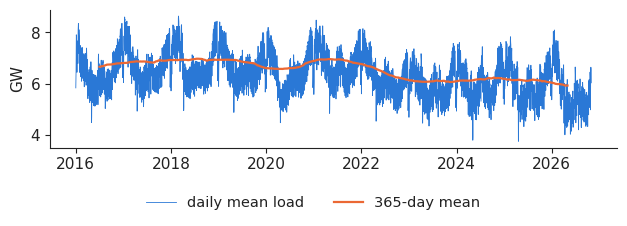

In [3]:
import matplotlib.dates as mdates
ld = pd.read_csv(DATA + 'ro_load_generation_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')['load']
ld = ld[(ld.index >= '2016-01-01') & (ld.index < '2026-11-01 00:00:00'.split(' ')[0] + ' 00:00+00:00')]
show('load.mean_mw', 'mean load (MW)', int(round(float(ld.mean()))))
s = ld.resample('D').mean()
fig, ax = plt.subplots(figsize=(6.4, 2.3))
ax.plot(s.index, s / 1000, color=PAL['data'], lw=.6, label='daily mean load'); ax.plot(s.index, s.rolling(365, center=True).mean() / 1000, color=PAL['model'], lw=1.6, label='365-day mean')
ax.set_ylabel('GW'); ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y')); legend_bottom(fig, ncol=2); fig.tight_layout(rect=(0, .15, 1, 1))
fig.savefig('load_series.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()